# 03. Exploratory Data Analysis and Financial Market Structure
Comprehensive empirical investigation of mutual fund assets, transaction flows, SIP adoption, and risk-return characteristics.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
fig_dir = Path('../reports')
fig_dir.mkdir(parents=True, exist_ok=True)
proc_dir = Path('../data/processed')

df_perf = pd.read_csv(proc_dir / 'fact_performance.csv')
df_txn = pd.read_csv(proc_dir / 'fact_transactions.csv')
df_sip = pd.read_csv(proc_dir / '04_monthly_sip_inflows.csv')


## Asset Under Management Concentration by Mutual Fund Category
Evaluating scheme count and total tracked AUM across mutual fund categories.


C:\Users\tanay\AppData\Local\Temp\ipykernel_18024\309257316.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cat_summary.index, y=cat_summary['total_aum_crore'], palette='viridis')


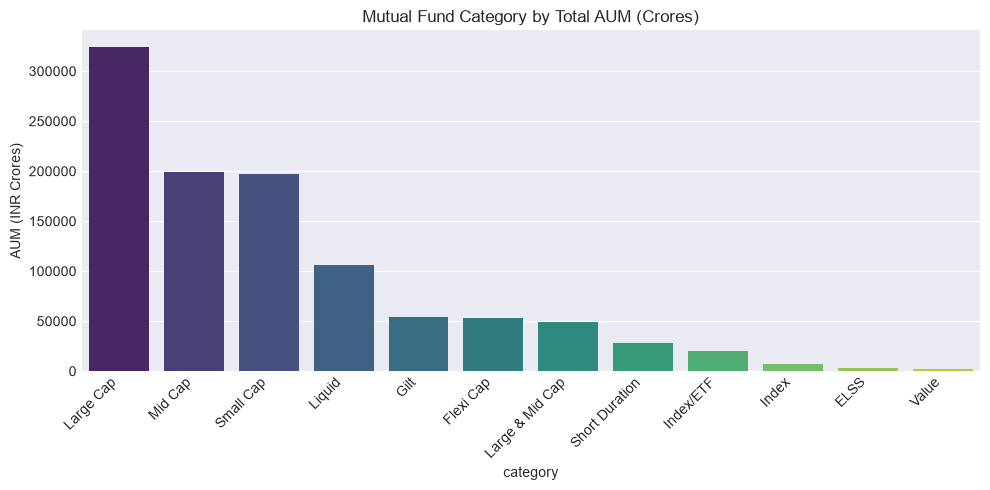

In [2]:
cat_summary = df_perf.groupby('category').agg(
    total_aum_crore=('aum_crore', 'sum'),
    scheme_count=('amfi_code', 'count'),
    avg_3yr_return=('return_3yr_pct', 'mean')
).sort_values(by='total_aum_crore', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=cat_summary.index, y=cat_summary['total_aum_crore'], palette='viridis')
plt.title('Mutual Fund Category by Total AUM (Crores)')
plt.xticks(rotation=45, ha='right')
plt.ylabel('AUM (INR Crores)')
plt.tight_layout()
plt.show()


## Monthly SIP Inflow Trajectories and Industry Account Expansion
Visualizing systematic investment plan momentum and account expansion over the four-year operational cycle.


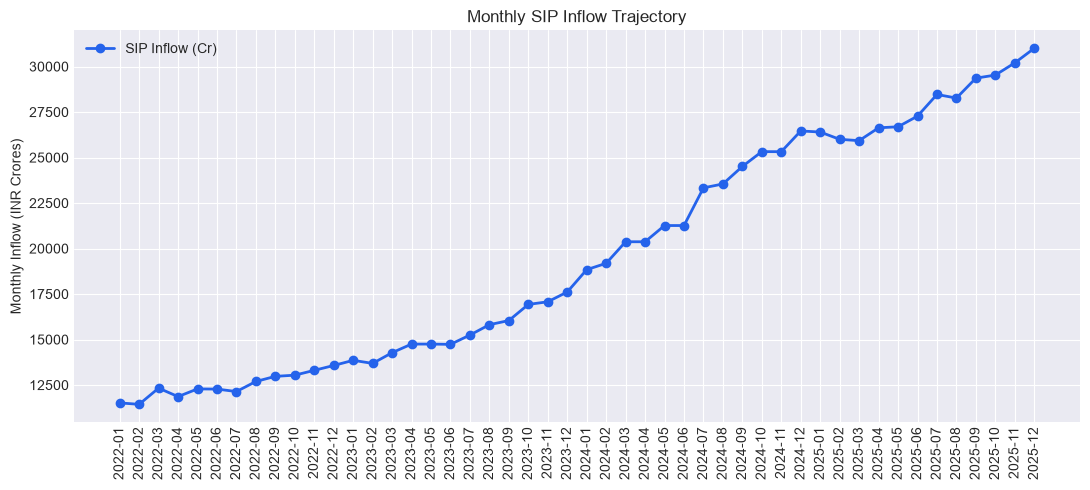

In [3]:
plt.figure(figsize=(11, 5))
plt.plot(df_sip['month'], df_sip['sip_inflow_crore'], marker='o', color='#2563EB', linewidth=2, label='SIP Inflow (Cr)')
plt.title('Monthly SIP Inflow Trajectory')
plt.xticks(rotation=90)
plt.ylabel('Monthly Inflow (INR Crores)')
plt.legend()
plt.tight_layout()
plt.show()


## Transaction Distribution and Capital Structure
Deconstructing the platform gross volume across ticket sizes and execution modes.


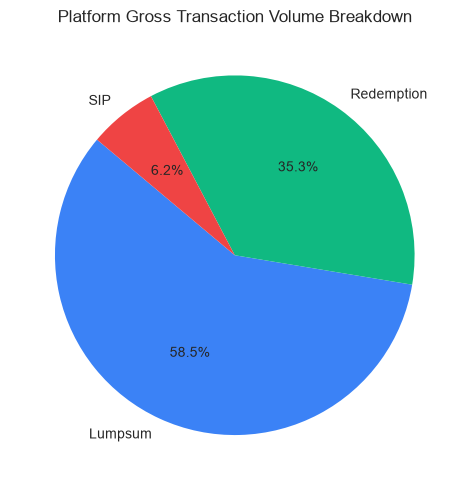

In [4]:
txn_summary = df_txn.groupby('transaction_type')['amount_inr'].sum()
plt.figure(figsize=(7, 5))
plt.pie(txn_summary, labels=txn_summary.index, autopct='%1.1f%%', colors=['#3B82F6', '#10B981', '#EF4444'], startangle=140)
plt.title('Platform Gross Transaction Volume Breakdown')
plt.tight_layout()
plt.show()


## Bivariate Risk-Return Profile: 3-Year Return vs Volatility
Evaluating risk-adjusted outperformance and category clustering across the universe of 40 funds.


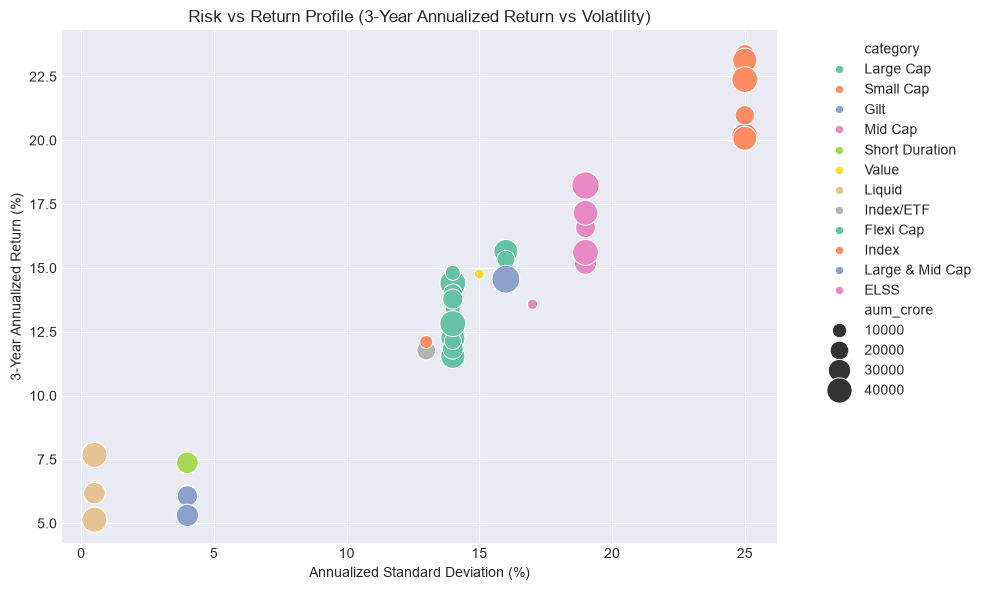

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_perf,
    x='std_dev_ann_pct',
    y='return_3yr_pct',
    hue='category',
    size='aum_crore',
    sizes=(40, 400),
    palette='Set2'
)
plt.title('Risk vs Return Profile (3-Year Annualized Return vs Volatility)')
plt.xlabel('Annualized Standard Deviation (%)')
plt.ylabel('3-Year Annualized Return (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(fig_dir / 'risk_return_scatter.png', dpi=300)
plt.show()
